# 11주차 — 오차 보정과 근거 설명 생성

- 11-1 이벤트 구간 식별 → 11-2 오차 보정(누수 검증) → 11-3 근거 구조화 → 11-4 설명문 생성 → 11-5 사실성 검증기 → 11-6 프롬프트 개선 루프
- 기준 예측 = 10주차 기본값 모델(Chronos-2 + 공변량)의 저장 예측. 보정 파라미터·이벤트 임계값은 **앞 26창**으로만 추정하고, 평가는 **뒤 26창**에서만 한다(10주차와 같은 분할).
- 장비: 노트북 CPU. LLM(gpt-4o-mini)은 11-4~11-6에서만, 이벤트 3건 × 3회 × 프롬프트 2종으로 호출.

In [1]:
import sys, os, json, time, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.stats import wilcoxon
from pandas.tseries.holiday import USFederalHolidayCalendar

ROOT = Path("..").resolve(); sys.path.append(str(ROOT))
from src import bench_models as bm, routing as rt, correction as cr, explain as ex
OUT = ROOT / "results/wk11"; OUT.mkdir(parents=True, exist_ok=True)
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if f in {x.name for x in font_manager.fontManager.ttflist}:
        plt.rcParams["font.family"] = f; break
plt.rcParams["axes.unicode_minus"] = False
rt.load_env()

H = rt.HORIZONS
data = bm.load_data(); weather, site = bm.load_weather(data)
state = pd.read_csv(ROOT / "results/wk10/state_signals.csv")
pools = {h: rt.Pool(data, h) for h in H}
FIT, EV = list(rt.FIT_W), list(rt.EVAL_W)
print("데이터", data.shape, "| 기준 모델:", cr.MODEL, "| 앞 26창 origin 끝:", pools[24].origin_ts[25], "| 뒤 26창 시작:", pools[24].origin_ts[26])

C:\Users\dong\miniconda3\envs\Self_directed_Project\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


데이터 (17544, 17) | 기준 모델: Chronos-2 + 공변량 | 앞 26창 origin 끝: 2017-07-02 00:00:00 | 뒤 26창 시작: 2017-07-09 00:00:00


## 과제 11-1. 이벤트 구간 식별

- **큰 오차**: 시간 단위 정규화 오차(|오차| ÷ 건물별 Naive 분모)가 **앞 26창의 95% 분위수**를 넘는 시간. 임계값을 앞 26창으로만 정함.
- **원인 분류** (우선순위 순): 공휴일(미국 연방 공휴일) → 극한 기온(사이트별 외기온 5% 미만/95% 초과, 앞 구간 기온으로 분위수) → 최근 급증(직전 1주 Naive MASE > 3, 10주차 R5와 같은 기준) → 원인 불명.
- 기온·달력은 예측 시점에 아는 값이라 11-2 보정의 '상황' 구분에도 같이 씀.

In [2]:
frames, thr_info = {}, {}
for h in H:
    df = cr.build_frame(pools[h], data, weather, site, state)
    df, temp_q = cr.add_categories(df, data, weather, pools[h].origin_ts[26])
    df, thr = cr.label_events(df, df["window"] < 26)
    frames[h], thr_info[h] = df, thr
    # 회귀 점검: 기준 모델의 뒤 26창 MASE 가 10주차 '최고 단일 모델'과 같은가
    m = cr.score_df(df, "pred", pools[h], EV)[0]
    print(f"{h}h 기준 모델 뒤 26창 MASE {m:.4f} | 큰 오차 임계값(정규화 오차 95%) {thr:.3f}")
prev = pd.read_csv(ROOT / "results/wk10/router_comparison.csv")
print(prev.iloc[:1].to_string(index=False))

24h 기준 모델 뒤 26창 MASE 0.3686 | 큰 오차 임계값(정규화 오차 95%) 1.100


168h 기준 모델 뒤 26창 MASE 0.7689 | 큰 오차 임계값(정규화 오차 95%) 2.284
 horizon                                   방식     MASE  평균 지연(ms/계열)  LLM 비용($)  LLM 응답 실패
      24 최고 단일 모델 (앞 26창 기준: Chronos-2 + 공변량) 0.368641     294.08345        NaN        NaN


cause  horizon   시간수  큰오차  평균정규화오차  큰오차 비율  전체 시간 중 비중  큰오차 중 비중  총 오차 중 비중
 극한기온       24   950   89    0.490   0.094       0.090     0.154      0.119
원인 불명       24  9236  420    0.347   0.045       0.871     0.728      0.820
최근 급증       24   422   68    0.561   0.161       0.040     0.118      0.061
  공휴일      168  2448  305    0.980   0.125       0.033     0.071      0.042
 극한기온      168  7646  537    0.838   0.070       0.103     0.125      0.112
원인 불명      168 61448 2367    0.565   0.039       0.828     0.553      0.608
최근 급증      168  2714 1070    4.991   0.394       0.037     0.250      0.237


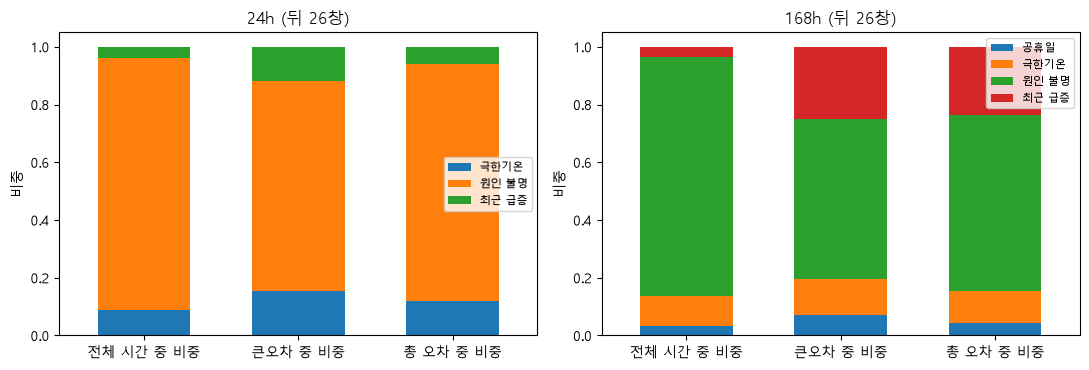

In [3]:
rows = []
for h in H:
    ev = frames[h][frames[h]["window"].isin(EV)]
    g = ev.groupby("cause").agg(시간수=("big", "size"), 큰오차=("big", "sum"), 평균정규화오차=("err", "mean"))
    g["큰오차 비율"] = g["큰오차"] / g["시간수"]
    g["전체 시간 중 비중"] = g["시간수"] / len(ev)
    g["큰오차 중 비중"] = g["큰오차"] / ev["big"].sum()
    g["총 오차 중 비중"] = ev.groupby("cause")["err"].sum() / ev["err"].sum()
    g.insert(0, "horizon", h)
    rows.append(g.reset_index())
causes = pd.concat(rows)
causes.to_csv(OUT / "event_causes.csv", index=False, encoding="utf-8")
print(causes.round(3).to_string(index=False))
top = []
for h in H:
    ev = frames[h][frames[h]["window"].isin(EV) & frames[h]["big"]].sort_values("err", ascending=False).head(20)
    top.append(ev.assign(horizon=h)[["horizon", "window", "building", "ts", "step", "y", "pred", "err", "temp", "hol", "recent", "cause"]])
pd.concat(top).to_csv(OUT / "event_top20.csv", index=False, encoding="utf-8")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, h in zip(ax, H):
    t = causes[causes["horizon"] == h].set_index("cause")[["전체 시간 중 비중", "큰오차 중 비중", "총 오차 중 비중"]]
    t.T.plot.bar(stacked=True, ax=a, width=.6, rot=0); a.set_title(f"{h}h (뒤 26창)"); a.set_ylabel("비중"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "event_causes.png", dpi=110); plt.show()

## 과제 11-2. 오차 보정 로직

3가지를 모두 구현: **상황별 오프셋**((건물, 상황)별 평균 잔차 가산, 상황 = 공휴일/극한고온/극한저온, 평시는 보정 안 함) · **조건부 스케일링**((건물, 기온 구간)별 배율 Σy/Σpred) · **잔차 모델**(정규화 잔차를 예측하는 작은 LightGBM).
- 보정 강도(수축 k)는 **앞 26창 안에서만** 고른다: 앞 13창으로 추정 → 다음 13창에서 검증. 뒤 26창은 보정을 정하는 데 쓰지 않음. 고른 뒤 앞 26창 전체로 다시 추정.
- 채점은 2주차 하네스(`score_backtest`). 대조군으로 **누수 보정**(52창 전체로 추정해 뒤 26창에 적용)도 같이 계산.

In [4]:
def fit_all(df, ks=None):
    """df 전체를 받아 내부에서 window<26 만 골라 쓴다 → 평가창 값이 바뀌어도 결과가 같아야 한다(아래 불변성 검사)."""
    fit = df[df["window"] < 26]
    ks = ks or {"offset": cr.select_k(fit, "offset")[0], "scale": cr.select_k(fit, "scale")[0]}
    return {"ks": ks, "offset": cr.fit_offset(fit, ks["offset"]), "offset_k0": cr.fit_offset(fit, 0), "scale": cr.fit_scale(fit, ks["scale"]),
            "res": cr.fit_resmodel(fit)}

def apply_all(df, P):
    d = df.copy()
    d["c_offset"] = cr.apply_offset(d, P["offset"]); d["c_offset_k0"] = cr.apply_offset(d, P["offset_k0"])
    d["c_scale"] = cr.apply_scale(d, P["scale"]); d["c_res"] = cr.apply_resmodel(d, P["res"])
    return d

fits, sel = {}, {}
for h in H:
    P = fit_all(frames[h]); fits[h] = P
    sel[h] = {kind: cr.select_k(frames[h][frames[h]["window"] < 26], kind)[1].assign(horizon=h, 방식=kind) for kind in ("offset", "scale")}
    frames[h] = apply_all(frames[h], P)
    print(h, "h 선택된 수축 k:", P["ks"], "(1e9 = 사실상 보정 없음)")
pd.concat([t for h in H for t in sel[h].values()]).to_csv(OUT / "correction_k_selection.csv", index=False, encoding="utf-8")
print(pd.concat([t for h in H for t in sel[h].values()]).round(4).to_string(index=False))

24 h 선택된 수축 k: {'offset': 1000000000.0, 'scale': 1000000000.0} (1e9 = 사실상 보정 없음)


168 h 선택된 수축 k: {'offset': 50.0, 'scale': 1000000000.0} (1e9 = 사실상 보정 없음)
           k  검증 정규화 MAE  horizon     방식
         0.0      0.5482       24 offset
        50.0      0.5461       24 offset
       200.0      0.5451       24 offset
      1000.0      0.5447       24 offset
1000000000.0      0.5446       24 offset
         0.0      0.4243       24  scale
        50.0      0.4019       24  scale
       200.0      0.3918       24  scale
      1000.0      0.3852       24  scale
1000000000.0      0.3840       24  scale
         0.0      1.0992      168 offset
        50.0      1.0911      168 offset
       200.0      1.0939      168 offset
      1000.0      1.0991      168 offset
1000000000.0      1.1022      168 offset
         0.0      0.7831      168  scale
        50.0      0.7199      168  scale
       200.0      0.7055      168  scale
      1000.0      0.6935      168  scale
1000000000.0      0.6866      168  scale


In [5]:
# 누수 대조군: 52창 전체로 추정 → 뒤 26창에 적용 (하면 안 되는 방식)
for h in H:
    df = frames[h]
    df["leak_offset"] = cr.apply_offset(df, cr.fit_offset(df, 0))
    df["leak_res"] = cr.apply_resmodel(df, cr.fit_resmodel(df))

METHODS = [("기준 (보정 없음)", "pred"), ("오프셋 (k 선택)", "c_offset"), ("오프셋 (k=0)", "c_offset_k0"), ("스케일링 (k 선택)", "c_scale"),
           ("잔차 모델", "c_res"), ("[누수] 오프셋 52창 추정", "leak_offset"), ("[누수] 잔차 모델 52창 추정", "leak_res")]
rows = []
for h in H:
    df = frames[h]; ev = df[df["window"].isin(EV)]; evt = ev[ev["cat"] != "평시"]
    base_m, base_pb = cr.score_df(df, "pred", pools[h], EV)
    base_evt = (evt["resid"].abs() / evt["denom"]).mean()
    for name, col in METHODS:
        m, pb = cr.score_df(df, col, pools[h], EV)
        e = ((evt["y"] - evt[col]).abs() / evt["denom"]).mean()
        d = (pb - base_pb)
        p = wilcoxon(pb, base_pb).pvalue if col != "pred" else np.nan
        rows.append({"horizon": h, "방식": name, "MASE(뒤 26창)": m, "기준 대비": m / base_m - 1, "이벤트 시간 정규화 MAE": e, "이벤트 기준 대비": e / base_evt - 1,
                     "개선 건물": int((d < 0).sum()), "악화 건물": int((d > 0).sum()), "Wilcoxon p": p, "이벤트 시간 수": len(evt)})
comp = pd.DataFrame(rows)
comp.to_csv(OUT / "correction_comparison.csv", index=False, encoding="utf-8")
print(comp.round(4).to_string(index=False))

 horizon                방식  MASE(뒤 26창)   기준 대비  이벤트 시간 정규화 MAE  이벤트 기준 대비  개선 건물  악화 건물  Wilcoxon p  이벤트 시간 수
      24        기준 (보정 없음)       0.3686  0.0000          0.4898     0.0000      0      0         NaN       950
      24        오프셋 (k 선택)       0.3686 -0.0000          0.4898    -0.0000     10      5      0.0884       950
      24         오프셋 (k=0)       0.3719  0.0089          0.5264     0.0747      5     10      0.0356       950
      24       스케일링 (k 선택)       0.3686  0.0000          0.4898    -0.0000     10      7      0.9265       950
      24             잔차 모델       0.3933  0.0669          0.5262     0.0742      4     13      0.0011       950
      24   [누수] 오프셋 52창 추정       0.3690  0.0010          0.4941     0.0087      9      8      0.7819       950
      24 [누수] 잔차 모델 52창 추정       0.3553 -0.0362          0.4737    -0.0329     11      6      0.0984       950
     168        기준 (보정 없음)       0.7689  0.0000          0.8728     0.0000      0      0         NaN     10094
 

24h 추정에 쓴 마지막 시각 2017-07-02 23:00:00 < 첫 평가 origin 2017-07-09 00:00:00
168h 추정에 쓴 마지막 시각 2017-07-02 23:00:00 < 첫 평가 origin 2017-07-03 00:00:00


 horizon        추정에 쓴 마지막 시각  오프셋 동일  스케일 동일  잔차 모델 동일  선택 k 동일
      24 2017-07-02 23:00:00    True    True      True     True
     168 2017-07-02 23:00:00    True    True      True     True


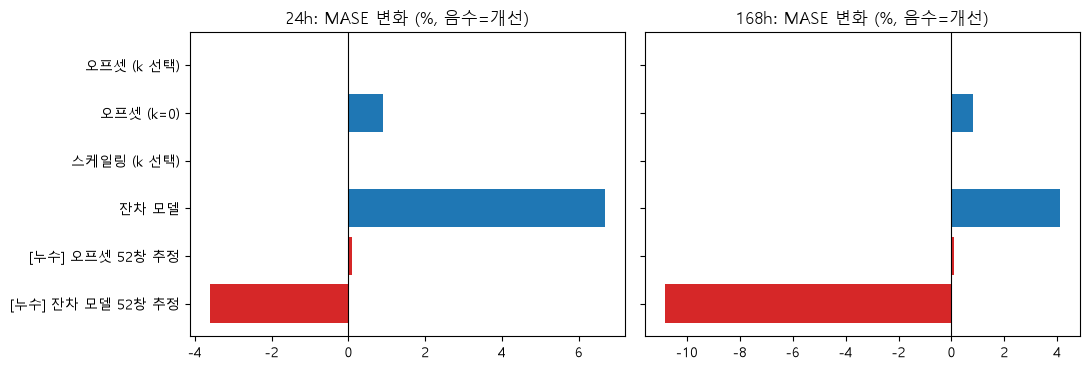

In [6]:
# 누수 없음 검증 ① 보정에 쓴 행의 마지막 시각이 첫 평가 origin 이전인가
for h in H:
    fit_rows = frames[h][frames[h]["window"] < 26]
    assert fit_rows["ts"].max() < pools[h].origin_ts[26]
    print(f"{h}h 추정에 쓴 마지막 시각 {fit_rows['ts'].max()} < 첫 평가 origin {pools[h].origin_ts[26]}")
# ② 불변성: 뒤 26창의 정답을 무작위로 바꿔도 보정 파라미터가 그대로인가
rng = np.random.default_rng(0)
chk = []
for h in H:
    d2 = frames[h][["window", "building", "b", "step", "ts", "y", "pred", "temp", "hol", "hour", "dow", "denom", "cat", "tbin"]].copy()
    m = d2["window"] >= 26
    d2.loc[m, "y"] = rng.permutation(d2.loc[m, "y"].to_numpy()); d2["resid"] = d2["y"] - d2["pred"]
    P2 = fit_all(d2)
    probe = frames[h][frames[h]["window"] < 26].head(2000)
    chk.append({"horizon": h, "추정에 쓴 마지막 시각": frames[h][frames[h]["window"] < 26]["ts"].max(),
                "오프셋 동일": P2["offset"] == fits[h]["offset"], "스케일 동일": P2["scale"] == fits[h]["scale"],
                "잔차 모델 동일": bool(np.allclose(cr.apply_resmodel(probe, P2["res"]), cr.apply_resmodel(probe, fits[h]["res"]))),
                "선택 k 동일": P2["ks"] == fits[h]["ks"]})
chk = pd.DataFrame(chk); chk.to_csv(OUT / "leak_checks.csv", index=False, encoding="utf-8"); print(chk.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, h in zip(ax, H):
    t = comp[comp["horizon"] == h].iloc[1:]
    a.barh(t["방식"][::-1], t["기준 대비"][::-1] * 100, color=["#d62728" if "누수" in n else "#1f77b4" for n in t["방식"][::-1]])
    a.axvline(0, color="k", lw=.8); a.set_title(f"{h}h: MASE 변화 (%, 음수=개선)")
plt.tight_layout(); plt.savefig(OUT / "correction_comparison.png", dpi=110); plt.show()

## 과제 11-3. 근거 데이터 구조화

이벤트 3건(24h, 뒤 26창의 큰 오차 시간): 원인별(극한 기온 / 최근 급증 / 원인 불명) 최대 오차 1건씩, 서로 다른 건물. (24h 뒤 26창에는 공휴일이 없음)
- SHAP은 Chronos-2를 직접 설명할 수 없어 **외기온을 포함해 origin 이전 데이터로 학습한 LightGBM 대리 모델**의 SHAP이다(JSON에 명시).
- 구간(interval) = 예측값 + 앞 26창 잔차의 10~90% 분위수(근사). 정답(실측)은 JSON에 넣지 않음(예측 시점 정보만).
- 이상 상태: `is_anomaly` = 직전 1주 Naive MASE > 3(10주차 R5 기준), 수준 라벨은 앞 26창 분포의 50/75/95% 기준.

In [7]:
h = 24; df = frames[h]
ctx = dict(pool=pools[h], df=df, data=data, weather=weather, site=site, route_log=pd.read_csv(ROOT / "results/wk10/routing_log_rule_24h.csv"),
           recent_q=state[state["window"] < 26]["recent_naive_mase"].quantile([.5, .75, .95]).tolist(),
           temp_q=cr.add_categories(df, data, weather, pools[h].origin_ts[26])[1], hol_days=USFederalHolidayCalendar().holidays(data.index.min(), data.index.max()))
big = df[df["window"].isin(EV) & df["big"]]
picks, used = [], set()
for cause in ["극한기온", "최근 급증", "원인 불명"]:
    for _, r in big[big["cause"] == cause].sort_values("err", ascending=False).iterrows():
        if r["building"] not in used:
            used.add(r["building"]); picks.append(dict(window=int(r["window"]), building=r["building"], step=int(r["step"]), cause=cause, err=float(r["err"]))); break
t0 = time.time()
EVID = [ex.build_evidence(p, ctx) for p in picks]
print(f"근거 구조화 {time.time()-t0:.0f}s"); print(pd.DataFrame(picks).to_string(index=False))
json.dump({"picks": picks, "evidence": EVID}, open(OUT / "evidence_events.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print(json.dumps(EVID[0], ensure_ascii=False, indent=1))

근거 구조화 17s
 window          building  step cause       err
     33  Fox_office_Vicki    12  극한기온 12.154260
     46 Bull_office_Sally    18 최근 급증  3.204483
     29    Fox_office_Joy    23 원인 불명 11.324597
{
 "building": "Fox_office_Vicki",
 "forecast_time": "2017-08-27 12:00:00",
 "horizon_h": 24,
 "prediction": {
  "value": 86.5,
  "unit": "kWh",
  "interval": [
   81.5,
   91.8
  ],
  "interval_note": "앞 26주 동안 이 건물의 잔차 10~90% 분위수를 더한 근사 구간",
  "model_used": "Chronos-2 + 공변량",
  "route_reason": "기본값 Chronos-2 + 공변량"
 },
 "shap_top_features": [
  {
   "feature": "lag_24",
   "value": 98.28,
   "contribution": -127.88
  },
  {
   "feature": "rolling_min_24",
   "value": 0.0,
   "contribution": 31.42
  },
  {
   "feature": "building",
   "value": "Fox_office_Vicki",
   "contribution": 21.65
  }
 ],
 "shap_note": {
  "explained_model": "LightGBM 대리 모델(Chronos-2 자체가 아님)",
  "base_value": 192.3,
  "surrogate_prediction": 158.08
 },
 "covariates": {
  "airTemperature_forecast": 40.0,
  "tempe

## 과제 11-4·11-5. 설명문 생성 + 자동 사실성 검증기 (프롬프트 v1)

v1 프롬프트는 교재 지시 그대로("제공된 수치만 사용, 없는 정보는 언급하지 말 것"). 같은 입력을 3회씩 호출(temperature 0이어도 결정이 흔들림이 10주차에서 확인됨).
검증기(`src/explain.py: verify`): 문장 속 수치를 모두 뽑아 JSON의 수치와 **표기한 자릿수까지 반올림해서** 대조(날짜·모델명·피처명 속 숫자 포함, 비율은 %도 허용) + JSON에 없는 외부 원인 어휘(계절·설비·행사·상대 시점)와 값을 부풀리는 한정어("40도 이상") + JSON에 없는 영문 식별자를 '근거 없는 주장'으로 계산.

In [8]:
REPS = 3
calls = []
def run_prompt(name, system):
    rows = []
    for i, (p, e) in enumerate(zip(picks, EVID)):
        for r in range(REPS):
            o = ex.call_llm(system, e); v = ex.verify(o["text"], e)
            calls.append(dict(prompt=name, tok_in=o["tok_in"], tok_out=o["tok_out"], secs=o["secs"]))
            rows.append({"prompt": name, "event": i + 1, "cause": p["cause"], "rep": r + 1, **{k: v[k] for k in ["n_numbers", "n_match", "n_mismatch", "n_unsupported", "mismatch_items", "unsupported_claims"]}, "text": o["text"]})
    return pd.DataFrame(rows)

def summarize(res):
    g = res.groupby("event").agg(원인=("cause", "first"), 수치개수=("n_numbers", "sum"), 일치=("n_match", "sum"), 불일치=("n_mismatch", "sum"), 근거없는주장=("n_unsupported", "sum"))
    tot = g[["수치개수", "일치", "불일치", "근거없는주장"]].sum()
    g.loc["합계"] = ["", *tot.tolist()]
    g["불일치율"] = g["불일치"].astype(float) / g["수치개수"].astype(float)
    g["회당 근거없는주장"] = g["근거없는주장"].astype(float) / ([REPS] * 3 + [REPS * 3])
    return g

res_v1 = run_prompt("v1", ex.PROMPTS["v1"])
res_v1.to_csv(OUT / "reports_v1.csv", index=False, encoding="utf-8")
print(summarize(res_v1).round(3).to_string())
for _, r in res_v1.iterrows():
    if r["n_mismatch"] or r["n_unsupported"]:
        print(f"\n[이벤트{r['event']} #{r['rep']}] 불일치 {r['mismatch_items']} | 근거없음 {r['unsupported_claims']}\n{r['text']}")

          원인  수치개수  일치  불일치  근거없는주장  불일치율  회당 근거없는주장
event                                               
1       극한기온    21  21    0       3   0.0      1.000
2      최근 급증    23  23    0       3   0.0      1.000
3      원인 불명    35  35    0       2   0.0      0.667
합계              79  79    0       8   0.0      0.889

[이벤트1 #1] 불일치 [] | 근거없음 ['한정어: 40도 이상']
Fox_office_Vicki 건물의 24시간 에너지 수요 예측치는 86.5 kWh입니다. 이 예측치는 81.5 kWh에서 91.8 kWh 사이의 범위로, 지난 26주 동안의 데이터를 기반으로 한 근사 구간입니다. 주요 요인으로는 24시간 전의 에너지 사용량과 건물 특성이 있으며, 기온은 40도 이상으로 예상됩니다. 현재 상태는 정상이며, 최근 잔차 수준도 정상입니다. 이 예측은 LightGBM 대리 모델을 사용하여 생성되었습니다.

[이벤트1 #2] 불일치 [] | 근거없음 ['한정어: 40도 이상']
Fox_office_Vicki 건물의 24시간 에너지 수요 예측치는 86.5 kWh입니다. 이 예측치는 81.5 kWh에서 91.8 kWh 사이의 범위로, 지난 26주 동안의 데이터를 기반으로 한 근사 구간입니다. 주요 요인으로는 24시간 전의 에너지 사용량과 건물 특성이 포함되며, 기온은 40도 이상으로 예상됩니다. 현재 상태는 정상이며, 최근 잔차 수준도 안정적입니다. 이 예측은 LightGBM 대리 모델을 사용하여 생성되었습니다.

[이벤트1 #3] 불일치 [] | 근거없음 ['한정어: 40도 이상']
Fox_office_Vicki 건물의 24시간 에너지 수요 예측치는 86.5 kWh입니다. 이 예측치는 81.5 kWh에서 

## 과제 11-6. 프롬프트 개선 루프

v1 실패 항목 → 지시로 바꾼 것(v2). JSON과 검증기는 그대로 두고 프롬프트만 바꿔 재측정한다.

In [9]:
FAILS = res_v1[(res_v1["n_mismatch"] > 0) | (res_v1["n_unsupported"] > 0)]
print("v1 실패 유형:")
print(pd.Series([x for l in FAILS["unsupported_claims"] for x in l] + ["수치불일치:" + x for l in FAILS["mismatch_items"] for x in l]).value_counts().to_string())

v1 실패 유형:
오늘             5
한정어: 40도 이상    3


In [10]:
PROMPT_V2 = (
    "당신은 건물 에너지 수요 예측 결과를 설비 담당자에게 설명하는 도우미입니다. 아래 JSON에 제공된 정보만 사용해 한국어로 5문장 이내로 설명하세요.\n"
    "규칙:\n"
    "1. 수치는 JSON 값을 한 글자도 바꾸지 말고 그대로 옮기세요(반올림·계산·단위 환산·범위 표현 금지). '~이상', '~이하', '약' 같은 한정어를 수치에 붙이지 마세요.\n"
    "2. 피처 이름은 JSON의 영문 이름(예: lag_24)을 그대로 쓰고, 풀어 쓸 때는 이름을 괄호로 함께 적으세요. 이름에 들어 있는 숫자를 다른 숫자로 바꾸지 마세요.\n"
    "3. 날짜·시각은 forecast_time 값을 그대로 쓰세요. '오늘/내일/어제/작년/올해' 같은 상대 시점 표현은 쓰지 마세요.\n"
    "4. JSON에 없는 원인(계절, 설비 상태, 행사, 고장 등)과 JSON에 없는 권고는 쓰지 마세요.\n"
    "5. shap_top_features는 shap_note의 대리 모델 기준이며 예측 모델(model_used)이 아님을 한 문장으로 밝히세요. contribution이 음수면 값을 낮추는 방향, 양수면 높이는 방향으로만 해석하세요.\n"
    "6. is_anomaly, recent_residual_level, temperature_band, is_holiday는 JSON 값 그대로 한 번씩 언급하세요."
)
ex.PROMPTS["v2"] = PROMPT_V2
res_v2 = run_prompt("v2", PROMPT_V2)
res_v2.to_csv(OUT / "reports_v2.csv", index=False, encoding="utf-8")
json.dump(ex.PROMPTS, open(OUT / "prompts.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
s1, s2 = summarize(res_v1), summarize(res_v2)
cmp_ = pd.concat({"v1": s1, "v2": s2}, axis=1)
cmp_.to_csv(OUT / "verification_table.csv", encoding="utf-8")
print(cmp_.round(3).to_string())
for _, r in res_v2.iterrows():
    if r["n_mismatch"] or r["n_unsupported"]:
        print(f"\n[v2 이벤트{r['event']} #{r['rep']}] 불일치 {r['mismatch_items']} | 근거없음 {r['unsupported_claims']}\n{r['text']}")
print("\n--- v2 예시 (이벤트 1, 1회) ---\n" + res_v2.iloc[0]["text"])

          v1                                        v2                                    
          원인 수치개수  일치 불일치 근거없는주장 불일치율 회당 근거없는주장     원인 수치개수   일치 불일치 근거없는주장 불일치율 회당 근거없는주장
event                                                                                     
1       극한기온   21  21   0      3  0.0     1.000   극한기온   35   35   0      0  0.0       0.0
2      최근 급증   23  23   0      3  0.0     1.000  최근 급증   55   55   0      0  0.0       0.0
3      원인 불명   35  35   0      2  0.0     0.667  원인 불명   40   40   0      0  0.0       0.0
합계             79  79   0      8  0.0     0.889         130  130   0      0  0.0       0.0

--- v2 예시 (이벤트 1, 1회) ---
2017-08-27 12:00:00에 Fox_office_Vicki 건물의 에너지 수요 예측 값은 86.5 kWh입니다. 이 예측은 81.5에서 91.8 kWh 사이의 구간에 해당합니다. 주요 피처인 lag_24는 -127.88의 기여도로 에너지 수요를 낮추는 방향으로 작용하고, rolling_min_24는 31.42로 수요를 높이는 방향으로 작용합니다. 현재 상태는 is_anomaly가 false이며, recent_residual_level은 normal입니다. 또한, temperature_band는 extreme_high이고, is_holiday는 false입니다. 이 예측은 LightGBM

In [11]:
# 호출 수 · 토큰 · 비용 (이 노트북 실행분만 센다)
cl = pd.DataFrame(calls)
PI, PO = float(os.environ.get("PRICE_IN_PER_M", "0")), float(os.environ.get("PRICE_OUT_PER_M", "0"))
cost = cl.groupby("prompt").agg(호출수=("secs", "size"), 입력토큰=("tok_in", "sum"), 출력토큰=("tok_out", "sum"), 평균지연_s=("secs", "mean"))
cost["비용($)"] = cost["입력토큰"] / 1e6 * PI + cost["출력토큰"] / 1e6 * PO
cost.loc["합계"] = cost.sum(); cost.loc["합계", "평균지연_s"] = cl["secs"].mean()
cost.to_csv(OUT / "llm_cost.csv", encoding="utf-8"); print(cost.round(5).to_string())
json.dump({"python": platform.python_version(), "model": os.environ.get("OPENAI_MODEL", "gpt-4o-mini"), "base_model": cr.MODEL,
           "fit_windows": [0, 25], "eval_windows": [26, 51], "events": picks, "reps": REPS, "k_selected": {str(h): fits[h]["ks"] for h in H}},
          open(OUT / "env.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

         호출수     입력토큰    출력토큰   평균지연_s    비용($)
prompt                                         
v1       9.0   4458.0  1276.0  2.58772  0.00143
v2       9.0   6834.0  1753.0  3.13517  0.00208
합계      18.0  11292.0  3029.0  2.86144  0.00351
